# Практическое задание №3


Используйте данные из файла **StudentPerformanceFactors.csv** с информацией о студентах.

[Источник](https://www.kaggle.com/datasets/lainguyn123/student-performance-factors/code)

В нём содержаться следующие переменные:

|    Название переменной     |                             Описание переменной                              |
| :------------------------: | :--------------------------------------------------------------------------: |
|       Hours_Studied        |                   Number of hours spent studying per week                    |
|         Attendance         |                        Percentage of classes attended                        |
|    Parental_Involvement    | Level of parental involvement in the student's education (Low, Medium, High) |
|    Access_to_Resources     |          Availability of educational resources (Low, Medium, High)           |
| Extracurricular_Activities |            Participation in extracurricular activities (Yes, No).            |
|        Sleep_Hours         |                 Average number of hours of sleep per night.                  |
|      Previous_Scores       |                         Scores from previous exams.                          |
|      Motivation_Level      |              Student's level of motivation (Low, Medium, High).              |
|      Internet_Access       |                  Availability of internet access (Yes, No).                  |
|     Tutoring_Sessions      |               Number of tutoring sessions attended per month.                |
|       Family_Income        |                   Family income level (Low, Medium, High).                   |
|      Teacher_Quality       |                 Quality of the teachers (Low, Medium, High).                 |
|        School_Type         |                  Type of school attended (Public, Private).                  |
|       Peer_Influence       |  Influence of peers on academic performance (Positive, Neutral, Negative).   |
|     Physical_Activity      |            Average number of hours of physical activity per week.            |
|   Learning_Disabilities    |                 Presence of learning disabilities (Yes, No).                 |
|  Parental_Education_Level  |   Highest education level of parents (High School, College, Postgraduate).   |
|     Distance_from_Home     |             Distance from home to school (Near, Moderate, Far).              |
|           Gender           |                    Gender of the student (Male, Female).                     |
|         Exam_Score         |                              Final exam score.                               |


In [208]:
# %pip install jupyterlab pandas openpyxl matplotlib kagglehub seaborn statsmodels scikit-learn scipy

In [232]:
import kagglehub
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import statsmodels.api as sm
from scipy import stats
from sklearn.preprocessing import StandardScaler
from statsmodels.stats.diagnostic import het_breuschpagan


In [ ]:
path = kagglehub.dataset_download(
    "lainguyn123/student-performance-factors",
    path="StudentPerformanceFactors.csv",
    output_dir="data",
    force_download=True,
)

100%|██████████| 627k/627k [00:03<00:00, 189kB/s]


In [233]:
df = pd.read_csv(path)

Выполните, пожалуйста, задания.


1. Используйте в качестве зависимой переменной при построении линейной регрессии переменную Exam_Score. Выберите не менее 3 категориальных и 3 метрических предикторов. Убедитесь, что не наблюдается высокой корреляции между метрическими предикторами, а категориальные предикторы не дублируют друг друга по значениям.


<h4 style="color: green">1. Решение</h4>

Для регрессионного анализа в качестве предикторов будем использовать

_числовые переменные:_

- Hours_Studied
- Attendance
- Previous_Scores

_категориальные переменные:_

- Motivation_Level (ординальная)
- Parental_Involvement (ординальная)
- Access_to_Resources (ординальная)

Переменные были выбраны на основе результатов ДЗ 1, где был проведен описательный анализ и выявлена взаимосвязь этих переменных и оценками у лучших студентов (отобранных по значению переменной `Exam_Score`). Для регрессионного анализа предпочтительно, чтобы была взаимосвязь зависимой переменной и предикторов


In [235]:
y = "Exam_Score"

numerical = ["Hours_Studied", "Attendance", "Previous_Scores"]
categorical = ["Motivation_Level", "Parental_Involvement", "Access_to_Resources"]

In [236]:
# проверка на мультиколлинеарность числовых предикторов
df[numerical + [y]].corr()

,Hours_Studied,Attendance,Previous_Scores,Exam_Score
Hours_Studied,1.000000,-0.009908,0.024846,0.445455
Attendance,-0.009908,1.000000,-0.020186,0.581072
Previous_Scores,0.024846,-0.020186,1.000000,0.175079
Exam_Score,0.445455,0.581072,0.175079,1.000000


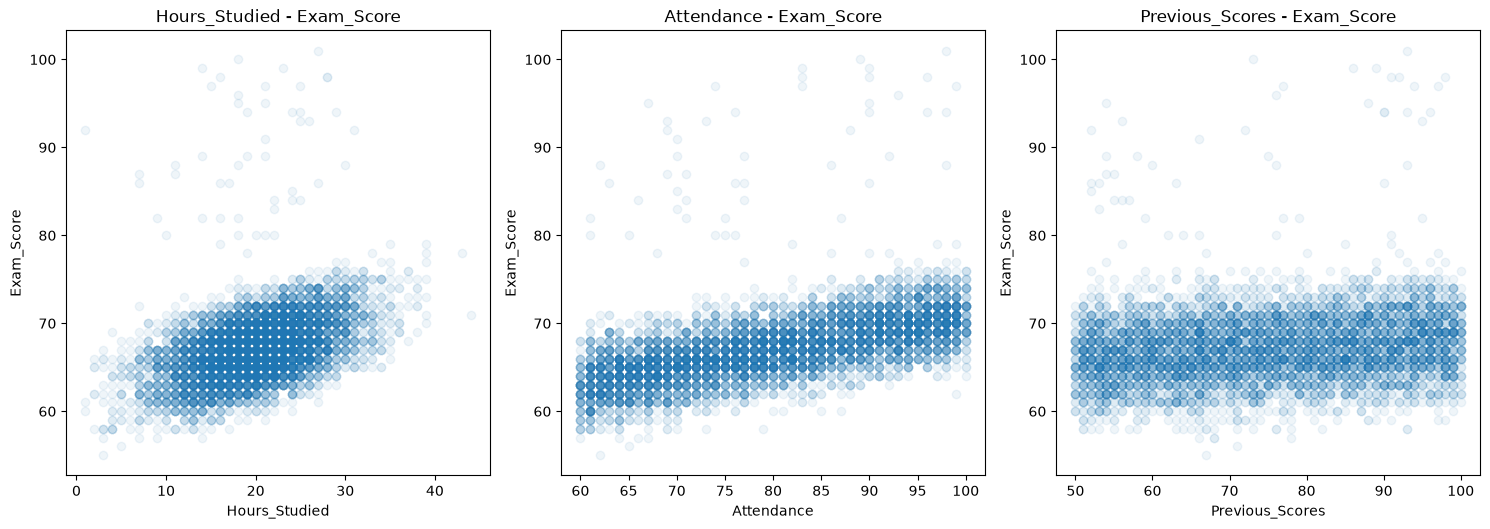

In [237]:
# визуализация взаимосвязи зависимой переменной и числовых предикторов

plt.figure(figsize=(15, 10))
for i, d in enumerate(numerical):
    plt.subplot(2, 3, i + 1)
    plt.scatter(df[d], df["Exam_Score"], alpha=0.07)
    plt.title(f"{d} - {y}")
    plt.xlabel(d)
    plt.ylabel(y)

plt.tight_layout()
plt.show()


In [190]:
# проверка на мультиколлинеарность категориальных предикторов
for col in categorical:
    display(df.groupby(col)["Exam_Score"].mean())

Motivation_Level
High      67.704321
Low       66.752194
Medium    67.330648
Name: Exam_Score, dtype: float64

Parental_Involvement
High      68.092767
Low       66.358265
Medium    67.098156
Name: Exam_Score, dtype: float64

Access_to_Resources
High      68.092152
Low       66.203351
Medium    67.134378
Name: Exam_Score, dtype: float64

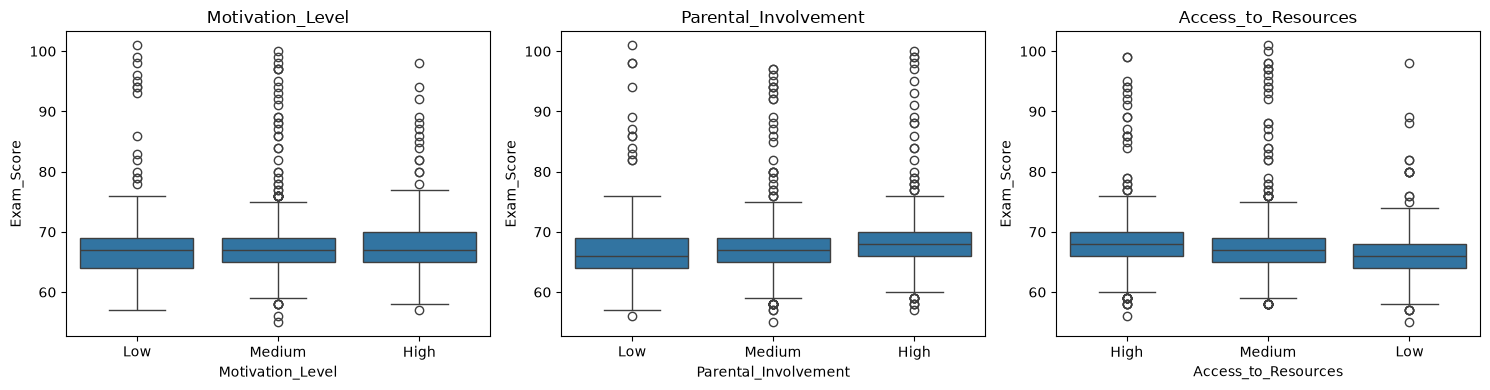

In [191]:
# визуализация взаимосвязи зависимой переменной и категориальных предикторов

plt.figure(figsize=(15, 4))

for i, col in enumerate(categorical):
    plt.subplot(1, 3, i + 1)
    sns.boxplot(data=df, x=col, y=y)
    plt.title(col)

plt.tight_layout()
plt.show()

2. Постройте модель множественной линейной регрессии использовав в качестве предикторов исходные метрические переменные или рассчитанные на их основе компоненты/индексы и категориальные предикторы. Напишите уравнение регрессии. Оцените характеристики регрессионной модели в целом.


In [ ]:
y = df["Exam_Score"]

# стандартизация числовых предикторов
X_num = pd.DataFrame(
    StandardScaler().fit_transform(df[numerical]), columns=numerical, index=df.index
)

# dummies-стандартизация категориальных предикторов
X_cat = [
    pd.get_dummies(df[cat], prefix=cat, drop_first=True, dtype=int)
    for cat in categorical
]

X = sm.add_constant(X_num.join(X_cat))

In [ ]:
# регрессионная модель
model = sm.OLS(y, X).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:             Exam_Score   R-squared:                       0.644
Model:                            OLS   Adj. R-squared:                  0.643
Method:                 Least Squares   F-statistic:                     1326.
Date:                Wed, 28 Oct 2026   Prob (F-statistic):               0.00
Time:                        13:26:54   Log-Likelihood:                -14939.
No. Observations:                6607   AIC:                         2.990e+04
Df Residuals:                    6597   BIC:                         2.997e+04
Df Model:                           9                                         
Covariance Type:            nonrobust                                         
                                  coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------------
const             

<span style='color: orange'>Описание</span>

Коэффициент детерминации (R2) показывает, что модель объясняет ок. 64% вариации `Exam_score`.

Adj.R2 почти совпадает, что указывает на небольшой штраф за излишние предикторы

f-statistic = 1326 / p-value < 0.05: модель статистически значима в целом.

Condition № = 6.53: Явных признаков сильной мультиколлинеарности не обнаружено

Обращает на себя внимание показатели распределения ошибок:

- Skewness (наклон): 7.742 > 1. сильный наклон вправо
- Kurtosis (заостренность): 85.418 > 3. очень сильная заостренность

<span style='color: green'>Вывод:</span> Модель объясняет большую часть различий в результатах экзаменов, но требует дополнительной диагностики остатков.


3. Оцените статистическую значимость регрессионных коэффициентов. Сравните их между собой по силе взаимосвязи с зависимой переменной. Подробно интерпретируйте особенности взаимосвязи между каждым из предикторов и зависимой переменной. Это очень важный пункт задания. Именно в нем мы узнаем, как именно каждый из предикторов взаимосвязан с зависимой переменной и какое изменение значений зависимой переменной можно ожидать при изменении значения предиктора на единицу.


<span style='color: green'>Вывод:</span>

Все коэффициенты статистически значимы: p < 0.05

Тк числовые предикторы стандартизированы, а категориальные нет, возможно сравнивать коэффициенты только внутри этих групп

По абсолютной величине стандартизированных коэффициентов, наибольшее влияние на зависимую переменную оказывают:

среди числовых

- `Attendance` (2.31)
- `Hours_Studied` (1.76)

среди категориальных

- `Access_to_Resources_Low` (-2.01: рарзница с референтной категорией)
- `Parental_Involvement_Low` (-2.01: рарзница с референтной категорией)

Тк для _числовые переменные_ были стандартизированны StandardScaler, увеличение стандартизированного числового предиктора на 1 увеличивает значение исходного предиктора на одно стандартное отклонение.

Все _категориальные предикторы_ показывают положительную связь с результатом экзамена: чем выше уровень мотивации, вовлечённости родителей и доступа к ресурсам, тем выше ожидаемый `Exam_Score`. Отрицательные коэффициенты категорий Low и Medium показывают, на сколько баллов их результаты ниже по сравнению с референтной категорией High.

> **Уравнение регрессии**
>
> `Exam_Score = 69.6525 + 1.7586*Hours_Studied_z + 2.3082*Attendance_z + 0.6789*Previous_Scores_z - 1.0825*Motivation_Level_Low - 0.5689*Motivation_Level_Medium - 2.0136*Parental_Involvement_Low - 1.0545*Parental_Involvement_Medium - 2.0114*Access_to_Resources_Low - 0.9299*Access_to_Resources_Medium`


4. Проведите диагностику модели. Оцените распределение остатков. Наблюдается ли гетероскедастичность, если да, то на основе чего сделан такой вывод? Сколько в модели выбросов и/или влияющих наблюдений?


In [ ]:
p_value = het_breuschpagan(model.resid, model.model.exog)[1]
print(f"Тест Бройша–Пагана на гомоскедантичность, p-value: {p_value:.2g}")
print("Остатки гомоскедантичны:", "Да" if p_value > 0.05 else "Нет")

Тест Бройша–Пагана на гомоскедантичность, p-value: 0.87
Остатки гомоскедантичны: Да


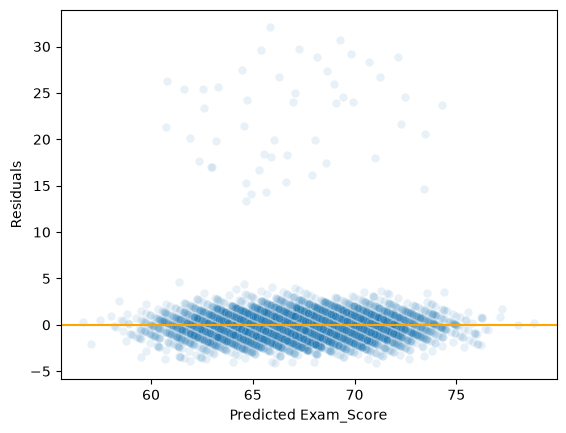

In [ ]:
sns.scatterplot(x=model.fittedvalues, y=model.resid, alpha=0.1)
plt.axhline(0, color="orange", linestyle="-")
plt.xlabel("Predicted Exam_Score")
plt.ylabel("Residuals")
plt.show()

<span style='color: green'>Вывод гетероскедастичности:</span>

Тест Бройша–Пагана показал p-value = 0.87 > 0.05, поэтому нет оснований отвергать гипотезу о гомоскедастичности

На графике большинство остатков распределены вокруг 0, форма не меняется. При этом присутствуют отдельные наблюдения с большими остатками.

Статистически значимых признаков гетероскедастичности не обнаружено.


In [220]:
inf_sum = model.get_influence().summary_frame()

/var/folders/lw/jr3fj8rn4n3cvbgtlrmh3yr00000gn/T/ipykernel_12601/3666953640.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(inf_sum['standard_resid'].dropna(), fit=stats.norm)


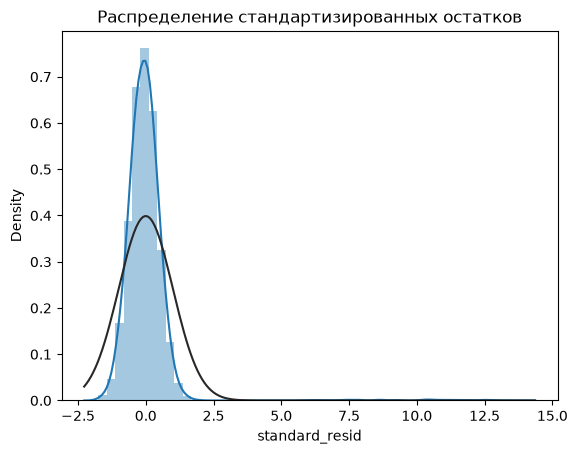

In [ ]:
sns.distplot(inf_sum["standard_resid"].dropna(), fit=stats.norm)
plt.title("Распределение стандартизированных остатков")
plt.show()

<span style='color: green'>Вывод нормальности распределения остатков:</span>

Остатки распределены ненормально. На графике виден правосторонний перекос и длинный хвост


In [ ]:
total = len(df)

outl_amount = (inf_sum["standard_resid"].abs() > 3).sum()
inf_amount = (inf_sum["cooks_d"] > 4 / len(X)).sum()

print(f"Выбросы: {outl_amount}, ({outl_amount / total:.2%})")
print(f"Влияющие наблюдения (Дистанция Кука): {inf_amount}, ({inf_amount / total:.2%})")

Выбросы: 50, (0.76%)
Влияющие наблюдения (Дистанция Кука): 54, (0.82%)


<span style='color: green'>Вывод о выбросах и влияющих наблюдениях:</span>

В регрессионной модели обнаружено 50 выбросов (0.76% выборки) и 54 потенциально влияющих наблюдения (0.82% выборки). Таких наблюдений немного, но они могут влиять на оценки коэффициентов регрессии и требуют дополнительного внимания. Они связаны с малым количеством выдающихся оценок (очень хорошо и отлично), разброс которых достаточно широкий


5. Сформулируйте общие содержательные выводы по результатам регрессионного анализа данных. Какие результаты анализа данных для вас оказались очевидными, а какие неожиданными?


<h3 style='color: green'>Общие выводы:</h3>

Модель объясняет около 64% вариации результатов экзамена. Все предикторы статистически значимы (p < 0.05).

**Ожидаемо:** самая сильная связь обнаружена у посещаемости и времени подготовки. Мотивация, вовлечённость родителей и доступ к ресурсам также связаны с результатами.

**Неожиданно:** предыдущие оценки оказались менее значимым предиктором, чем посещаемость.

Модель удовлетворительно описывает различия в успеваемости, но ненормальное распределение остатков и наличие выбросов затрудняют интерпретацию результата


**Комментарии к заданию и принципам его оценивания:**

- Все пункты задания должны сопровождаться выполненным фрагментом кода. В этом задании будет проверяться корректность работы кода, то есть будут последовательно запущены ячейки, чтобы убедиться, что код не выдаст ошибку в какой-то момент. Перед отправкой работы на проверку рекомендуется "прогнать" код.
- Если Вы получили результаты в виде статистических показателей, таблиц или графиков, при этом никак их не прокомментировали и не сформулировали содержательные выводы на их основе, то работа оценивается в 0 баллов, в этом случае анализ данных не проведён.
- Если Вы полностью выполнили это задание, то получаете за него 8 баллов (отлично). Для получения более высокой оценки нужно выйти за рамки предложенного задания. В случае с текущим заданием это может быть дополнительное самостоятельное изучение инструментов регрессионного анализа и их применение, или развернутое и глубокое исследование имеющихся данных на основе использования пройденных на занятиях методов.
- В этом задании 5 пунктов. Первый весит 15%, второй - 20%, третий - 40%, четвертый - 20%, пятый - 5%.


### Этот файл нужно сохранить как Jupyter Notebook (.ipynb) и отправить на amelikyan@hse.ru до 21:00 3 ноября.
